# *SIRD MODEL*

In [1]:
# Cell 1: import base
import numpy as np
import matplotlib.pyplot as plt

# (facoltativo) per riproducibilità
rng = np.random.default_rng(42)

# piccoli helper per grafici "step"
def step_plot(t, y, label):
    plt.step(t, y, where='post', label=label)

In [2]:
# Cell 2: Gillespie SIRD essenziale
def gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=np.inf, rng=None):
    """
    Simula una traiettoria SIRD con SSA (Gillespie).
    Reazioni:
      1) Infezione:  S + I -> I + I     (tasso: beta * S*I/N)
      2) Guarigione: I -> R             (tasso: gamma * I)
      3) Decesso:    I -> D             (tasso: mu * I)
    Stato assorbente: qualsiasi stato con I == 0.
    """
    if rng is None:
        rng = np.random.default_rng()

    N = S0 + I0 + R0 + D0
    t = 0.0
    S, I, R, D = S0, I0, R0, D0

    T = [t]
    X = [(S, I, R, D)]

    while t < t_max:
        # propensioni
        a1 = beta * S * I / N
        a2 = gamma * I
        a3 = mu * I
        a0 = a1 + a2 + a3

        # se nessun evento è possibile, fermati (I=0 => a0=0)
        if a0 <= 0:
            break

        # tempo al prossimo evento ~ Exp(a0)
        tau = rng.exponential(1.0 / a0)
        t += tau

        # scegli reazione
        r = rng.random()
        if r < a1 / a0:
            # infezione
            if S > 0:
                S -= 1
                I += 1
        elif r < (a1 + a2) / a0:
            # guarigione
            if I > 0:
                I -= 1
                R += 1
        else:
            # decesso
            if I > 0:
                I -= 1
                D += 1

        T.append(t)
        X.append((S, I, R, D))

        # stato assorbente: I == 0
        if I == 0:
            break

    return np.array(T), np.array(X, dtype=int)

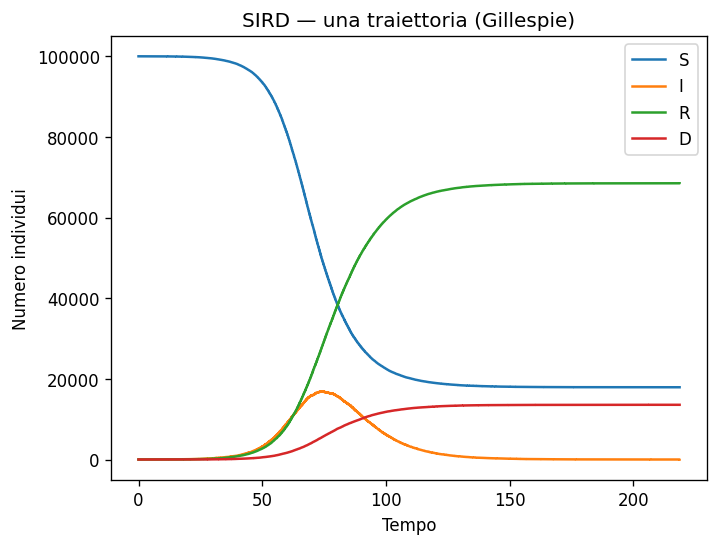

Tempo finale: 218.64987760794034
Stato finale (S, I, R, D): (np.int64(17919), np.int64(0), np.int64(68511), np.int64(13570))
Assorbimento raggiunto? I==0 -> True


In [147]:
# Cell 3: esempio singola traiettoria
N = 100000
S0, I0, R0, D0 = N-1, 1, 0, 0

# Parametri (modificali liberamente)
beta = 0.25   # contagio
gamma = 0.10  # guarigione
mu    = 0.02  # mortalità

t, traj = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=365, rng=rng)

plt.figure(dpi=120)
step_plot(t, traj[:,0], 'S')
step_plot(t, traj[:,1], 'I')
step_plot(t, traj[:,2], 'R')
step_plot(t, traj[:,3], 'D')
plt.xlabel('Tempo')
plt.ylabel('Numero individui')
plt.title('SIRD — una traiettoria (Gillespie)')
plt.legend()
plt.show()

print("Tempo finale:", t[-1])
print("Stato finale (S, I, R, D):", tuple(traj[-1]))
print("Assorbimento raggiunto? I==0 ->", traj[-1,1] == 0)

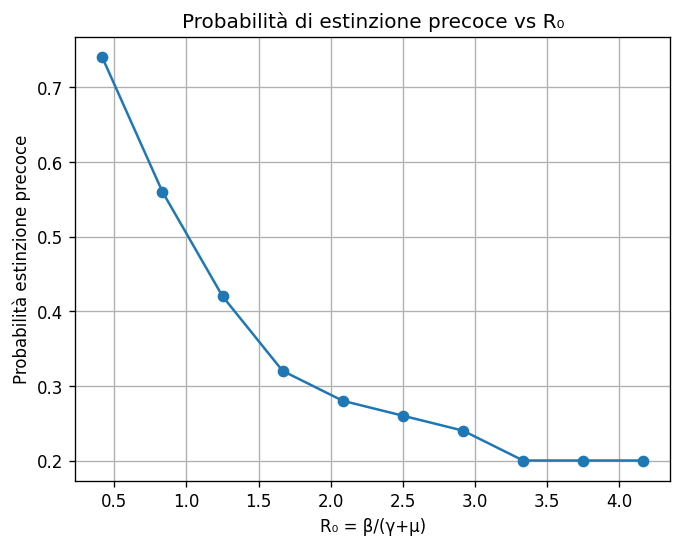

In [21]:
# Cell 4: ensemble di simulazioni per stimare probabilità di estinzione
def simulate_many(n_runs, S0, I0, R0, D0, beta, gamma, mu, t_max=100, seed=0):
    rng = np.random.default_rng(seed)
    results = []
    for k in range(n_runs):
        t, traj = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max, rng=np.random.default_rng(seed + k))
        results.append(traj)
    return results

def early_extinction(traj):
    """Restituisce True se I non cresce mai oltre il valore iniziale."""
    I = traj[:,1]
    return I.max() == I[0]

# Parametri fissi
N = 1000
S0, I0, R0, D0 = N-1, 1, 0, 0
gamma, mu = 0.1, 0.02

# Sweep su beta per stimare prob estinzione
betas = np.linspace(0.05, 0.5, 10)
ext_probs = []

for b in betas:
    runs = simulate_many(50, S0, I0, R0, D0, b, gamma, mu, t_max=100)
    extinct = sum(early_extinction(tr) for tr in runs)
    ext_probs.append(extinct / len(runs))

R0_vals = betas / (gamma + mu)

plt.figure(dpi=120)
plt.plot(R0_vals, ext_probs, marker='o')
plt.xlabel('R₀ = β/(γ+μ)')
plt.ylabel('Probabilità estinzione precoce')
plt.title('Probabilità di estinzione precoce vs R₀')
plt.grid(True)
plt.show()

In [24]:
# Cell 5: classificazione assorbente e riepilogo
def classify_absorbing_state(traj, I0=1):
    """
    Tutti gli stati finali hanno I==0 (assorbenti).
    Distinguiamo:
      - 'early_extinction': I non supera mai I0 (nessuna crescita)
      - 'epidemic': I supera I0 almeno una volta (c'è stata crescita)
    """
    I = traj[:,1]
    if I.max() <= I0:
        return 'early_extinction'
    else:
        return 'epidemic'

def batch_summary(n_runs, params, t_max=200, seed=123):
    S0, I0, R0, D0, beta, gamma, mu = params
    runs = []
    for k in range(n_runs):
        t, tr = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=t_max,
                               rng=np.random.default_rng(seed+k))
        runs.append((t, tr))
    classes = [classify_absorbing_state(tr, I0=I0) for _, tr in runs]
    p_ext = sum(c=='early_extinction' for c in classes)/len(classes)
    print(f"β={beta:.3f}, γ={gamma:.3f}, μ={mu:.3f}, R0≈{beta/(gamma+mu):.2f}")
    print(f"Frazione estinzioni precoci: {p_ext:.2f} ({sum(c=='early_extinction' for c in classes)}/{len(classes)})")
    return runs, classes

# Esempio di riepilogo per un set di parametri
N = 1000
params = (N-1, 1, 0, 0, 0.25, 0.10, 0.02)  # (S0,I0,R0,D0,beta,gamma,mu)
runs, classes = batch_summary(40, params, t_max=150)

β=0.250, γ=0.100, μ=0.020, R0≈2.08
Frazione estinzioni precoci: 0.28 (11/40)


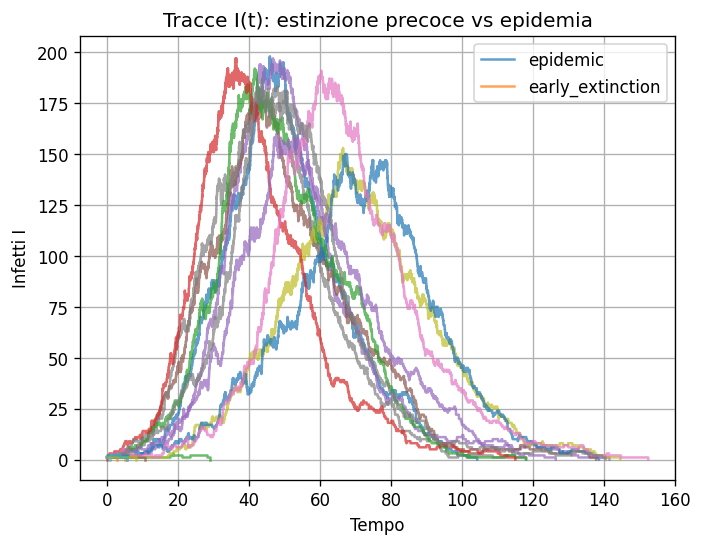

In [25]:
# Cell 6: visualizza alcune traiettorie distinguendo le classi
plt.figure(dpi=120)

# Mostriamo solo I(t) per chiarezza
shown = min(20, len(runs))
for i in range(shown):
    t, tr = runs[i]
    lab = 'early_extinction' if classes[i]=='early_extinction' else 'epidemic'
    # uso la label solo per le prime occorrenze per non duplicare in legenda
    plt.step(t, tr[:,1], where='post', alpha=0.7, label=lab if lab not in plt.gca().get_legend_handles_labels()[1] else None)

plt.xlabel('Tempo')
plt.ylabel('Infetti I')
plt.title('Tracce I(t): estinzione precoce vs epidemia')
plt.legend()
plt.grid(True)
plt.show()

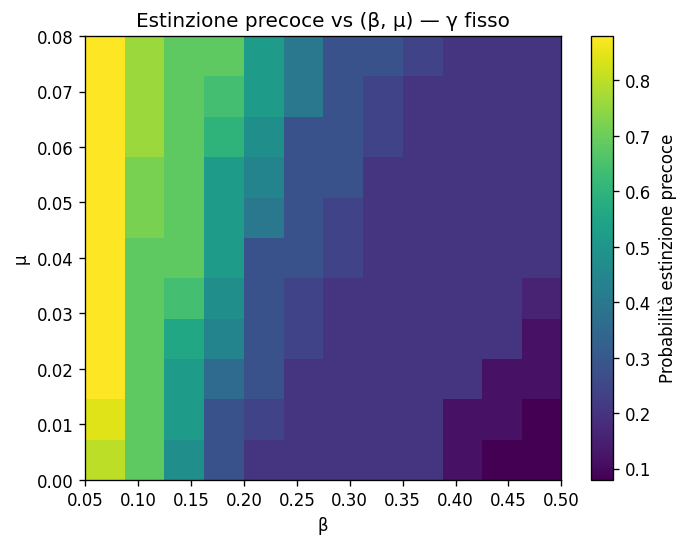

In [26]:
# Cell 7: heatmap estinzione precoce in funzione di (beta, mu)
N = 1000
S0, I0, R0, D0 = N-1, 1, 0, 0
gamma = 0.10

betas = np.linspace(0.05, 0.5, 12)
mus   = np.linspace(0.00, 0.08, 11)

P = np.zeros((len(mus), len(betas)))

for i, mu in enumerate(mus):
    for j, beta in enumerate(betas):
        # poche run per velocità; aumenta a 50–100 per maggiore affidabilità
        n = 25
        ext = 0
        for k in range(n):
            t, tr = gillespie_sird(S0, I0, R0, D0, beta, gamma, mu, t_max=120,
                                   rng=np.random.default_rng(1000 + 37*k))
            if classify_absorbing_state(tr, I0=I0) == 'early_extinction':
                ext += 1
        P[i, j] = ext / n

plt.figure(dpi=120)
im = plt.imshow(P, origin='lower', aspect='auto',
                extent=[betas[0], betas[-1], mus[0], mus[-1]])
plt.colorbar(im, label='Probabilità estinzione precoce')
plt.xlabel('β')
plt.ylabel('μ')
plt.title('Estinzione precoce vs (β, μ) — γ fisso')
plt.show()

# *Variazione con possibilità di riammalarsi* -> *SIRS-D*

In [27]:
import numpy as np
import matplotlib.pyplot as plt

def gillespie_sirsd(S0, I0, R0, D0, beta, gamma, mu, omega, t_max=np.inf, rng=None):
    """
    SIRS-D con Gillespie:
      1) S + I -> I + I        (a1 = beta * S*I / N)
      2) I -> R                (a2 = gamma * I)
      3) I -> D                (a3 = mu * I)
      4) R -> S                (a4 = omega * R)
    Stati assorbenti: I == 0 (malattia estinta, con S=N-D, R=0) oppure D == N (tutti morti).
    """
    if rng is None:
        rng = np.random.default_rng()
    N = S0 + I0 + R0 + D0

    t = 0.0
    S, I, R, D = S0, I0, R0, D0
    T = [t]
    X = [(S, I, R, D)]

    while t < t_max:
        a1 = beta * S * I / N
        a2 = gamma * I
        a3 = mu * I
        a4 = omega * R
        a0 = a1 + a2 + a3 + a4

        if a0 <= 0:
            break

        t += rng.exponential(1.0 / a0)
        r = rng.random()

        if r < a1 / a0:
            if S > 0:
                S -= 1; I += 1
        elif r < (a1 + a2) / a0:
            if I > 0:
                I -= 1; R += 1
        elif r < (a1 + a2 + a3) / a0:
            if I > 0:
                I -= 1; D += 1
        else:
            if R > 0:
                R -= 1; S += 1

        T.append(t)
        X.append((S, I, R, D))

        # assorbimento
        if I == 0 or D == N:
            break

    return np.array(T), np.array(X, dtype=int)

In [28]:
def classify_outcome(traj, N=None):
    """
    Restituisce 'all_dead' se D==N (tutti morti),
    altrimenti 'all_alive' quando I==0 e rimangono vivi (S+R>0).
    """
    S, I, R, D = traj[-1]
    if N is None:
        N = traj[-1].sum()
    if D == N:
        return 'all_dead'
    if I == 0:
        return 'all_alive'
    return 'ongoing'  # non dovrebbe capitare se lasci t_max abbastanza lungo

def step_plot(t, y, label):
    plt.step(t, y, where='post', label=label)

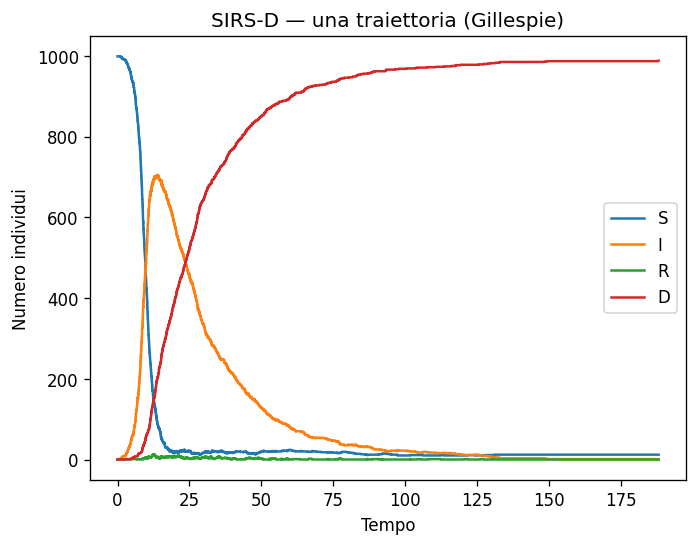

Stato finale (S, I, R, D): (np.int64(12), np.int64(0), np.int64(0), np.int64(988))
Esito: all_alive


In [132]:
# Parametri esempio
N = 1000
S0, I0, R0, D0 = N-1, 1, 0, 0
beta  = 0.7
gamma = 0.01
mu    = 0.05
omega = 1   # perdita d'immunità (R -> S)

rng = np.random.default_rng(7)
t, traj = gillespie_sirsd(S0, I0, R0, D0, beta, gamma, mu, omega, t_max=1000, rng=rng)

plt.figure(dpi=120)
step_plot(t, traj[:,0], 'S')
step_plot(t, traj[:,1], 'I')
step_plot(t, traj[:,2], 'R')
step_plot(t, traj[:,3], 'D')
plt.xlabel('Tempo'); plt.ylabel('Numero individui')
plt.title('SIRS-D — una traiettoria (Gillespie)')
plt.legend(); plt.show()

print("Stato finale (S, I, R, D):", tuple(traj[-1]))
print("Esito:", classify_outcome(traj, N))

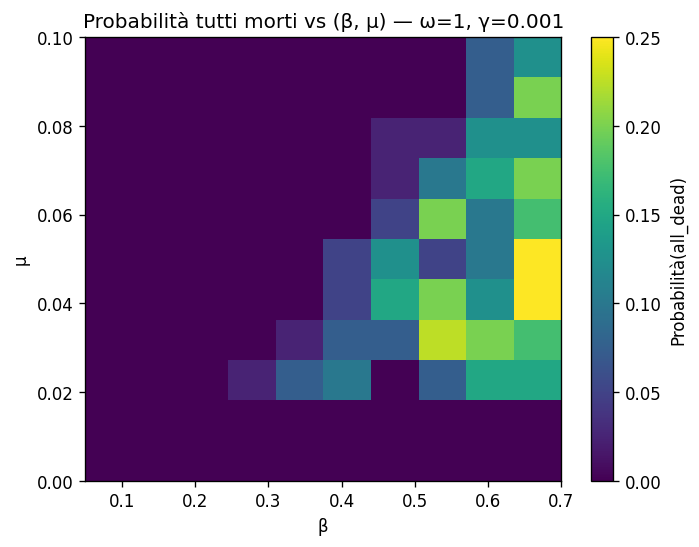

In [125]:
def estimate_all_dead_prob(n_runs, S0, I0, R0, D0, beta, gamma, mu, omega, t_max=1000, seed=0):
    dead = 0
    for k in range(n_runs):
        t, tr = gillespie_sirsd(S0, I0, R0, D0, beta, gamma, mu, omega,
                                t_max=t_max, rng=np.random.default_rng(seed+k))
        dead += (classify_outcome(tr, N=S0+I0+R0+D0) == 'all_dead')
    return dead / n_runs

# Sweep su beta e mu a omega fisso
N = 1000
S0, I0, R0, D0 = N-1, 1, 0, 0
gamma = 0.001
omega = 1

betas = np.linspace(0.05, 0.7, 10)
mus   = np.linspace(0.00, 0.10, 11)

Pdead = np.zeros((len(mus), len(betas)))
for i, mu in enumerate(mus):
    for j, beta in enumerate(betas):
        Pdead[i, j] = estimate_all_dead_prob(40, S0, I0, R0, D0, beta, gamma, mu, omega, t_max=365, seed=1000+37*(i*len(betas)+j))

plt.figure(dpi=120)
im = plt.imshow(Pdead, origin='lower', aspect='auto',
                extent=[betas[0], betas[-1], mus[0], mus[-1]])
plt.colorbar(im, label='Probabilità(all_dead)')
plt.xlabel('β'); plt.ylabel('μ')
plt.title(f'Probabilità tutti morti vs (β, μ) — ω={omega}, γ={gamma}')
plt.show()